In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter
from shapely.geometry import box
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.colors import to_rgb

In [2]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

SERIF = "Libertinus Serif"
FONTMAP = Path("fonts") 

beschikbaar = {f.name for f in font_manager.fontManager.ttflist}
if SERIF not in beschikbaar:
    print(f"{SERIF} niet gevonden; matplotlib valt terug op CMU Serif.")

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [SERIF, "CMU Serif", "DejaVu Serif"],
    "font.size": CORPS,
    "axes.titlesize": CORPS,
    "axes.labelsize": CORPS,
    "xtick.labelsize": CORPS,
    "ytick.labelsize": CORPS,
    "legend.fontsize": CORPS,
    "mathtext.fontset": "custom",
    "mathtext.rm": SERIF,
    "mathtext.it": f"{SERIF}:italic",
    "mathtext.bf": f"{SERIF}:bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
    "savefig.transparent": True,
    "savefig.dpi": 300,
})

def figsize(fractie=1.0, ratio=0.58):
    breedte = TEKSTBREEDTE * fractie
    return (breedte, breedte * ratio)

DATA = Path("../../data/algemeen")
DATA_HOOFDSTUK = Path("../../data/H4")
FIGUREN = Path("../../fig/H4")
FIGUREN.mkdir(exist_ok=True)

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [3]:
from matplotlib.font_manager import FontProperties, findfont
print(findfont(FontProperties(family="serif")).split("/")[-1])  # enkel de bestandsnaam

LibertinusSerif-Regular.otf


Kolom 'number' ontbreekt — exporteer de CSV opnieuw mét de supportkolom.


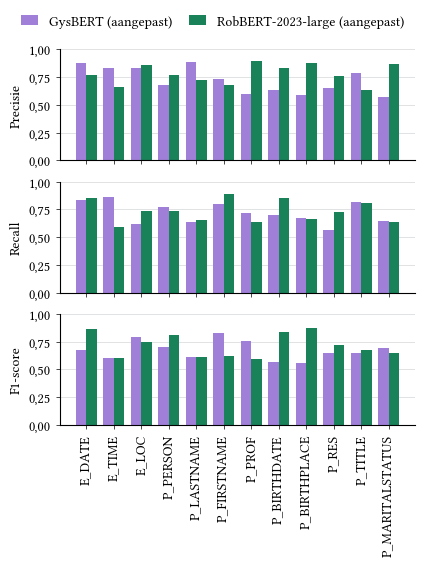

In [4]:
KLEUR_A = KLEUR_HOOFD
KLEUR_B = KLEUR_VROEG

SCORES = DATA_HOOFDSTUK / "F1__Precisie_en_Recall_per_entiteit.csv"

DATASET = "NER-fine-50"

ENTITEITEN = [
    "E_DATE", "E_TIME", "E_LOC", "P_PERSON", "P_LASTNAME", "P_FIRSTNAME",
    "P_PROF", "P_BIRTHDATE", "P_BIRTHPLACE", "P_RES", "P_TITLE", "P_MARITALSTATUS",
]

KLEUREN = {
    "gysbert-adapted": KLEUR_B,
    "robbert-2023-dutch-large-adapted": KLEUR_A,
}

LABELS = {
    "gysbert-adapted": "GysBERT (aangepast)",
    "robbert-2023-dutch-large-adapted": "RobBERT-2023-large (aangepast)",
}

METRIEKEN = {"precision": "Precisie", "recall": "Recall", "f1": "F1-score"}

# --- Data --------------------------------------------------------------
df = pd.read_csv(SCORES)
d_set = df[df["dataset"] == DATASET]

metrieken = [m for m in ["precision", "recall", "f1"]
             if m in d_set["metric"].str.lower().values]
entiteiten = [e for e in ENTITEITEN if e in d_set["entity"].values]

# aantallen per entiteit voor bij de aslabels
if "number" in d_set.columns:
    aantallen = d_set.groupby("entity")["number"].first()
    aslabels = [f"{e} ({aantallen[e]:,})".replace(",", ".") for e in entiteiten]
else:
    aslabels = entiteiten
    print("Kolom 'number' ontbreekt — exporteer de CSV opnieuw mét de supportkolom.")

# --- Figuur ------------------------------------------------------------
breedte = 0.38
x = np.arange(len(entiteiten))

fig, axes = plt.subplots(
    len(metrieken), 1, figsize=(TEKSTBREEDTE, 5.2),
    sharex=True, constrained_layout=True,
)

for ax, metriek in zip(axes, metrieken):
    d = d_set[d_set["metric"].str.lower() == metriek]
    for i, model in enumerate(m for m in KLEUREN if m in d["model"].values):
        reeks = d.loc[d["model"] == model].set_index("entity")["score"]
        ax.bar(
            x + (i - 0.5) * breedte,
            reeks.reindex(entiteiten).fillna(0).to_numpy(),
            width=breedte,
            color=KLEUREN[model],
            label=LABELS.get(model, model),
        )

    ax.set_ylabel(METRIEKEN.get(metriek, metriek))
    ax.set_ylim(0, 1)
    ax.set_yticks(np.arange(0, 1.01, 0.25))
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(length=3, width=0.5)

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(aslabels, rotation=90)

fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, loc="lower center",
           bbox_to_anchor=(0.5, 1.0), ncol=2, handlelength=1.2, columnspacing=1.2)

bestand = FIGUREN / f"4.1_ner_{DATASET.lower().replace('-', '_')}_scores_per_entiteit"
pas_breedte_aan(fig, tight=True)
fig.savefig(bestand.parent / f"{bestand.name}.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

In [5]:
breed = (
    d_set.pivot_table(index=["entity", "model"], columns="metric",
                      values="score", aggfunc="first")
)
breed["f1_verwacht"] = (
    2 * breed["precision"] * breed["recall"] / (breed["precision"] + breed["recall"])
)
breed["afwijking"] = (breed["f1"] - breed["f1_verwacht"]).abs().round(3)
print(breed.sort_values("afwijking", ascending=False).round(3))

metric                                               f1  precision  recall  \
entity          model                                                        
E_TIME          gysbert-adapted                   0.601      0.833   0.864   
E_DATE          gysbert-adapted                   0.674      0.875   0.833   
P_TITLE         gysbert-adapted                   0.646      0.785   0.817   
P_FIRSTNAME     robbert-2023-dutch-large-adapted  0.620      0.677   0.890   
P_PROF          robbert-2023-dutch-large-adapted  0.596      0.895   0.635   
P_LASTNAME      gysbert-adapted                   0.610      0.887   0.638   
P_AGE           robbert-2023-dutch-large-adapted  0.784      0.696   0.628   
                gysbert-adapted                   0.748      0.552   0.729   
P_BIRTHPLACE    robbert-2023-dutch-large-adapted  0.870      0.880   0.663   
P_PROF          gysbert-adapted                   0.752      0.601   0.721   
P_BIRTHDATE     gysbert-adapted                   0.569      0.6